# Chapitre 7 - Exercices 7.7 à 7.12

Ces exercices portent sur la seconde moitié du chapitre : LoRA, fusion de modèles et
tactiques de finetuning.

- **7.7** : compter les paramètres LoRA (GPT-3, Llama 2, service multi-LoRA) et repérer
  une incohérence dans un tableau ;
- **7.8** : LoRA à la main : initialisation, gradients, rang, coût de la version non
  fusionnée ;
- **7.9** : quel rang pour notre tâche ? (mini-lab : LoRA r = 1, 4, 32 sur Qwen2.5-0.5B) ;
- **7.10** : soupes de modèles (moyenner plusieurs finetunings d'une même tâche) ;
- **7.11** : SLERP : démonstrations et fusion en cascade de trois modèles ;
- **7.12** : accumulation de gradient, normalisation par token et poids de la perte du
  prompt.

In [1]:
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, annotate_bars
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
c7.setup_style()
llm.seed_everything(0)
GB = 1e9

## Exercice 7.7 : Compter les paramètres LoRA

**Énoncé.**

1. Retrouver le calcul du livre pour GPT-3 175B (96 couches, $d = 12\,288$) : LoRA de rang
   2 sur $W_q, W_k, W_v, W_o$. Combien de paramètres pour le rang 8 sur $W_q$ seul ?
2. Le tableau 7-6 du livre annonce, pour Llama 2-13B (40 couches, $d = 5\,120$) et
   « $r = 2$, matrices query et key », 3,28 M paramètres et 6,55 Mo. Vérifier. Que
   constate-t-on ? Même vérification pour la ligne GPT-3 (18,87 M).
3. Service multi-LoRA (section *Serving LoRA adapters*) : avec une matrice $4096 \times 4096$
   et $r = 8$, comparer le stockage de 100 modèles fusionnés et de 1 base + 100
   adaptateurs. À partir de combien de clients l'option séparée est-elle 10 fois plus
   économe ?

**Rappels.** Cours 3, sections 3 et 5 : un adaptateur de rang $r$ sur une matrice
$d_{out} \times d_{in}$ a $r(d_{in} + d_{out})$ paramètres ; on l'applique à chaque couche.

**Solution.**

*1.* Par matrice : $2 \times (12\,288 + 12\,288) = 49\,152$ ; quatre matrices, 96 couches :
$49\,152 \times 4 \times 96 = 18\,874\,368$. Rang 8 sur $W_q$ seul :
$8 \times 24\,576 \times 96 = 18\,874\,368$ : exactement le même budget, c'était le but.

*2.* Llama 2-13B, $r = 2$ sur $W_q$ et $W_k$ : $2 \times 10\,240 \times 2 \times 40 = 1\,638\,400$
paramètres, soit **1,64 M**, pas 3,28 M. Les 3,28 M correspondent aux **quatre** matrices
d'attention ($\times 2$). Même constat pour GPT-3 : 18,87 M est le nombre pour quatre
matrices, $W_q, W_k$ seuls donnent 9,44 M. Les mémoires (6,55 Mo, 37,7 Mo) sont cohérentes
avec les nombres annoncés à 2 octets par paramètre. Le libellé « query & key » de la
colonne semble donc erroné, ou les nombres correspondent à quatre matrices ; la conclusion
du tableau (l'adaptateur est minuscule devant les poids) reste vraie.

*3.* Fusionnés : $100 \times 16{,}78$ M $= 1{,}68$ Md ; séparés :
$16{,}78\text{ M} + 100 \times 65\,536 = 23{,}3$ M, 72 fois moins. Le rapport vaut
$n \cdot 16{,}78\text{M} / (16{,}78\text{M} + 65\,536\, n)$ : il dépasse 10 dès $n \ge 11$.

In [2]:
gpt3 = {"hidden_size": 12288, "num_attention_heads": 96, "intermediate_size": 49152, "num_hidden_layers": 96}
llama13 = {"hidden_size": 5120, "num_attention_heads": 40, "intermediate_size": 13824, "num_hidden_layers": 40}
att4 = ["q_proj", "k_proj", "v_proj", "o_proj"]
rows = []
for name, cfg_, dm in [("Llama 2-13B", llama13, 5120), ("GPT-3 175B", gpt3, 12288)]:
    qk = c7.lora_params_for_model(cfg_, ["q_proj", "k_proj"], 2)
    a4 = c7.lora_params_for_model(cfg_, att4, 2)
    rows.append({"modèle": name, "r=2, q et k (M)": qk / 1e6, "r=2, q, k, v, o (M)": a4 / 1e6,
                 "mémoire 16 bits, q et k (Mo)": qk * 2 / 1e6, "mémoire 16 bits, q k v o (Mo)": a4 * 2 / 1e6})
display(pd.DataFrame(rows).set_index("modèle").round(2))
print("GPT-3, r=8 sur Wq seul :", c7.lora_params_for_model(gpt3, ["q_proj"], 8))
W, ad = 4096 * 4096, c7.lora_param_count(4096, 4096, 8)
n = np.arange(1, 101)
ratio = n * W / (W + n * ad)
print(f"100 clients : fusion {100 * W / 1e9:.2f} Md, séparés {(W + 100 * ad) / 1e6:.1f} M ; rapport > 10 dès n = {n[np.argmax(ratio > 10)]}")

,"r=2, q et k (M)","r=2, q, k, v, o (M)","mémoire 16 bits, q et k (Mo)","mémoire 16 bits, q k v o (Mo)"
modèle,,,,
Llama 2-13B,1.64,3.28,3.28,6.55
GPT-3 175B,9.44,18.87,18.87,37.75


GPT-3, r=8 sur Wq seul : 18874368
100 clients : fusion 1.68 Md, séparés 23.3 M ; rapport > 10 dès n = 11


**Vérification graphique.**

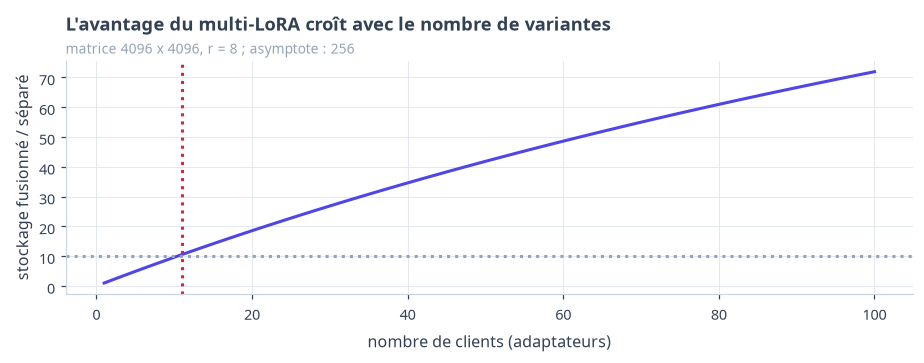

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(n, ratio, color=INDIGO)
ax.axhline(10, color=GRAY, ls=":"); ax.axvline(n[np.argmax(ratio > 10)], color=ROSE, ls=":")
ax.set_xlabel("nombre de clients (adaptateurs)"); ax.set_ylabel("stockage fusionné / séparé")
c7.title_sub(ax, "L'avantage du multi-LoRA croît avec le nombre de variantes", "matrice 4096 x 4096, r = 8 ; asymptote : 256")
plt.tight_layout(); plt.show()

> **À retenir.** $r(d_{in}+d_{out})$ par matrice et par couche : un calcul simple, à
> refaire soi-même plutôt que de recopier un tableau. Le stockage multi-LoRA tend vers un
> rapport $d_{in} d_{out} / (r(d_{in}+d_{out}))$ (ici 256).

## Exercice 7.8 : LoRA à la main

**Énoncé.** Pour une couche LoRA $y = Wx + \frac{\alpha}{r} BAx$ avec $W$ gelée :

1. Exprimer $\partial L / \partial A$ et $\partial L / \partial B$ en fonction de
   $g = \partial L / \partial y$. En déduire pourquoi on n'initialise pas $A$ **et** $B$ à
   zéro, et pourquoi initialiser **l'une** des deux à zéro suffit à démarrer du modèle de base.
2. Montrer que $\text{rang}(BA) \le r$.
3. Compter les opérations (multiplications-additions) par token pour la version non
   fusionnée et la version fusionnée, pour $d_{in} = d_{out} = 4096$ et $r = 8$.
4. Vérifier 1 et 2 numériquement.

**Rappels.** Cours 3, section 3 : `c7.make_lora_linear_class` initialise $A$ aléatoirement
et $B$ à zéro.

**Solution.**

*1.* Avec $u = Ax$ et $c = \alpha/r$ : $\partial L/\partial B = c\, g\, u^\top = c\, g\, (Ax)^\top$ et
$\partial L/\partial A = c\, B^\top g\, x^\top$. Si $A = B = 0$, les deux gradients sont nuls :
l'adaptateur ne bouge **jamais** (point selle). Si seulement $B = 0$, alors $BA = 0$
(départ exact du modèle de base) mais $\partial L/\partial B = c\, g\,(Ax)^\top \ne 0$ : $B$
apprend dès le premier pas, puis $A$ reçoit un gradient non nul.

*2.* L'image de $BA$ est incluse dans celle de $B$, engendrée par ses $r$ colonnes :
$\text{rang}(BA) \le \text{rang}(B) \le r$.

*3.* Fusionnée : $d_{in} d_{out} = 16{,}8$ M opérations par token. Non fusionnée :
$d_{in}d_{out} + r\,d_{in} + r\,d_{out} = 16{,}8\text{ M} + 65\,536$, soit +0,4 % d'opérations.
Le surcoût observé en pratique (cours 3, section 7) vient surtout des lancements de
noyaux supplémentaires et des petites matrices peu efficaces sur GPU, pas du nombre
d'opérations.

In [4]:
LoRALinear = c7.make_lora_linear_class()
torch.manual_seed(0)
x = torch.randn(16, 32); target = torch.randn(16, 24)
rows = []
for init in ["A aléatoire, B = 0", "A = 0, B = 0", "A et B aléatoires"]:
    lay = LoRALinear(torch.nn.Linear(32, 24, bias=False), r=4, alpha=8)
    with torch.no_grad():
        if init == "A = 0, B = 0":
            lay.A.zero_()
        if init == "A et B aléatoires":
            lay.B.normal_(0, 0.1)
    out0 = lay(x)
    loss = ((out0 - target) ** 2).mean(); loss.backward()
    rows.append({"initialisation": init, "écart initial au modèle de base": (out0 - lay.base(x)).abs().max().item(),
                 "||dL/dA||": lay.A.grad.norm().item(), "||dL/dB||": lay.B.grad.norm().item()})
display(pd.DataFrame(rows).set_index("initialisation"))
ranks = [torch.linalg.matrix_rank(torch.randn(64, r) @ torch.randn(r, 64)).item() for r in [1, 2, 4, 8, 16]]
print("rang de BA pour r = 1, 2, 4, 8, 16 :", ranks)
d_, r_ = 4096, 8
print(f"opérations par token : fusionnée {d_ * d_:,}, non fusionnée {d_ * d_ + r_ * 2 * d_:,} (+{r_ * 2 * d_ / d_ ** 2:.2%})".replace(",", " "))

,écart initial au modèle de base,||dL/dA||,||dL/dB||
initialisation,,,
"A aléatoire, B = 0",0.000000,0.000000,0.196613
"A = 0, B = 0",0.000000,0.000000,0.000000
A et B aléatoires,0.874478,0.296231,0.321837


rang de BA pour r = 1, 2, 4, 8, 16 : [1, 2, 4, 8, 16]
opérations par token : fusionnée 16 777 216  non fusionnée 16 842 752 (+0.39%)


**Vérification.** Le tableau confirme l'analyse : seule l'initialisation « $B = 0$, $A$
aléatoire » part exactement du modèle de base **et** reçoit un gradient non nul (sur $B$).
Avec $A$ et $B$ aléatoires, on apprendrait aussi, mais le modèle de départ serait perturbé.

> **À retenir.** $B = 0$ et $A$ aléatoire : départ exact du modèle de base et apprentissage
> immédiat. Le rang de la mise à jour est borné par $r$, et la version non fusionnée ne
> coûte que $r(d_{in}+d_{out})$ opérations de plus par token.

## Exercice 7.9 : Quel rang pour notre tâche ?

**Énoncé.** Sur la tâche des tickets (cours 3, section 6), entraîner des LoRA de rang 1,
4 et 32 (avec $\alpha = 2r$, mêmes données, 2 époques) et comparer : paramètres
entraînables, perte de validation, format et catégorie sur les formulations inédites.
Conclure sur le choix du rang à la lumière de la section *LoRA configurations*.

**Rappels.** Le livre rapporte qu'un rang de 4 à 64 suffit généralement et qu'augmenter
$r$ au-delà apporte peu (voire nuit par sur-apprentissage) ; cours 3, section 3 : le rang
doit égaler la complexité de la mise à jour nécessaire.

**Solution.** Deux effets s'opposent. D'un côté, la tâche (imposer un format, choisir
parmi quelques valeurs) semble demander une mise à jour de faible complexité, ce qui
plaide pour un petit rang. De l'autre, avec $\alpha = 2r$ le facteur d'échelle est le même
pour tous les rangs, mais un adaptateur de rang 1 n'a que 0,55 M paramètres pour absorber
le gradient : avec un budget fixe de 40 pas, il peut ne pas avoir le temps de converger.
Seule l'expérience tranche.

In [5]:
train_t = c7.make_tickets(160, seed=0)
val_t = c7.make_tickets(24, seed=2, split="test")
test_out = c7.make_tickets(48, seed=3, split="test")
from transformers import AutoConfig

cfgq = AutoConfig.from_pretrained(llm.SMALL).to_dict()
llm.free_gpu()
rank_runs = {r: c7.gpu_retry(c7.lora_ticket_run, train_t, val=val_t, eval_sets={"hors distribution": test_out}, r=r)
             for r in [1, 4, 32]}
c7.log_vram("ex rank")
rk = pd.DataFrame({f"r = {r}": {"paramètres entraînables (M)": c7.lora_params_for_model(cfgq, c7.LORA_TARGETS, r) / 1e6,
                                "perte de validation finale": v["history"].val_loss[-1],
                                **v["scores"]["hors distribution"], "durée (s)": v["history"].seconds}
                   for r, v in rank_runs.items()}).T
rk.round(3)

,paramètres entraînables (M),perte de validation finale,format valide,catégorie exacte,urgence exacte,durée (s)
r = 1,0.550,0.662,0.146,0.146,0.104,7.352
r = 4,2.200,0.414,1.000,0.750,0.708,7.338
r = 32,17.596,0.362,1.000,0.938,1.000,7.634


**Vérification graphique.**

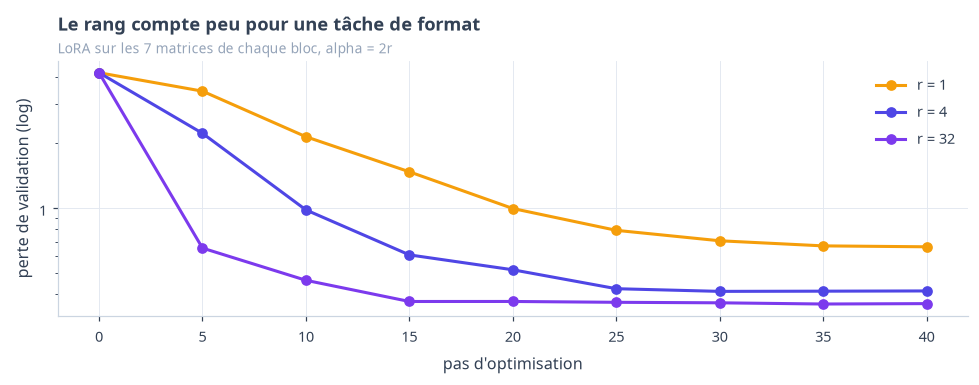

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for (r, v), col in zip(rank_runs.items(), [AMBER, INDIGO, VIOLET]):
    h = v["history"]
    ax.plot(h.val_step, h.val_loss, "o-", color=col, label=f"r = {r}")
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("pas d'optimisation"); ax.set_ylabel("perte de validation (log)"); ax.legend()
c7.title_sub(ax, "Le rang compte peu pour une tâche de format", "LoRA sur les 7 matrices de chaque bloc, alpha = 2r")
plt.tight_layout(); plt.show()

Résultat à lire dans le tableau : avec ce budget d'entraînement (2 époques, 40 pas), le
rang 1 n'a pas encore appris le format, alors que les rangs 4 et 32 l'ont appris ; le rang
32 obtient ici les meilleurs scores de champs. Le livre note justement que le rang optimal
varie selon les cas (Raschka trouve $r = 256$ optimal sur ses tâches) : un « petit rang
suffit » n'est pas une loi. Deux précautions avant de conclure : avec 48 tickets, quelques
points d'écart ne sont pas significatifs, et un rang 1 entraîné plus longtemps (ou avec un
taux plus élevé) rattraperait sans doute une partie du retard. Le rang interagit donc avec
le taux d'apprentissage et le nombre de pas : on le règle avec eux, sur l'évaluation.

> **À retenir.** Le rang se règle expérimentalement, avec le taux d'apprentissage et le
> budget d'entraînement : un rang trop faible peut ne pas converger dans le temps imparti.
> 8 à 32 est un point de départ raisonnable ; le coût mémoire de LoRA reste faible même à
> rang 32 (17,6 M paramètres ici).

## Exercice 7.10 : Soupes de modèles

**Énoncé.** Les *model soups* (Wortsman et al., 2022) moyennent plusieurs finetunings
d'une **même** tâche obtenus avec des hyperparamètres différents. Sur le réseau `digits`
(`c7.digits_merge_setup`), finetuner la base sur la tâche « occulté » avec six réglages
(taux d'apprentissage et graines différents), puis comparer :

- le meilleur finetuning individuel (choisi sur une validation) ;
- la **soupe uniforme** (moyenne des six) ;
- la **soupe gloutonne** : on trie les modèles par score de validation, puis on ajoute
  chaque modèle à la soupe seulement s'il améliore la validation.

Pourquoi une moyenne de poids peut-elle faire mieux que chacun des modèles ?

**Rappels.** Cours 4, section 2 : la combinaison linéaire fonctionne bien pour des modèles
finetunés depuis la même base, qui restent dans le même « bassin » de la fonction de perte.

**Solution.** Des finetunings partis de la même base avec de petits pas restent proches
les uns des autres ; dans cette région, la perte est à peu près convexe. La moyenne de
points d'une région convexe a une perte au plus égale à la moyenne de leurs pertes
(inégalité de Jensen), et se situe souvent plus près du fond de la cuvette, dans une zone
plus plate qui généralise mieux. La soupe gloutonne protège contre les ingrédients
nuisibles (un finetuning parti trop loin). Vérifions.

In [7]:
S = c7.digits_merge_setup()
Xtr, ytr, Xte, yte = S.tasks["occulté"]
rng = np.random.default_rng(0)
perm = rng.permutation(len(Xtr)); val_idx, tr_idx = perm[:250], perm[250:]
ingredients = []
for i, (lr, seed) in enumerate([(3e-4, 0), (5e-4, 1), (1e-3, 2), (2e-3, 3), (5e-4, 4), (1e-3, 5)]):
    net = c7.make_mlp(0, S.hidden); c7.set_flat(net, S.base)
    c7.fit_mlp(net, Xtr[tr_idx], ytr[tr_idx], epochs=12, lr=lr, seed=seed)
    v = c7.get_flat(net)
    ingredients.append({"réglage": f"lr={lr:g}, graine {seed}", "vec": v,
                        "val": c7.accuracy(net, Xtr[val_idx], ytr[val_idx]), "test": c7.accuracy(net, Xte, yte)})


def acc_of(vec, X, y):
    net = c7.make_mlp(0, S.hidden); c7.set_flat(net, vec); return c7.accuracy(net, X, y)


uniform = np.mean([g["vec"] for g in ingredients], 0)
order = sorted(ingredients, key=lambda g: -g["val"])
soup = [order[0]["vec"]]
for g in order[1:]:
    cand = soup + [g["vec"]]
    if acc_of(np.mean(cand, 0), Xtr[val_idx], ytr[val_idx]) >= acc_of(np.mean(soup, 0), Xtr[val_idx], ytr[val_idx]):
        soup = cand
greedy = np.mean(soup, 0)
best_ind = order[0]
summary = pd.DataFrame({
    "validation": [g["val"] for g in ingredients] + [acc_of(uniform, Xtr[val_idx], ytr[val_idx]), acc_of(greedy, Xtr[val_idx], ytr[val_idx])],
    "test": [g["test"] for g in ingredients] + [acc_of(uniform, Xte, yte), acc_of(greedy, Xte, yte)]},
    index=[g["réglage"] for g in ingredients] + ["soupe uniforme (6)", f"soupe gloutonne ({len(soup)})"])
summary.round(3)

,validation,test
"lr=0.0003, graine 0",0.892,0.844
"lr=0.0005, graine 1",0.888,0.869
"lr=0.001, graine 2",0.920,0.869
"lr=0.002, graine 3",0.924,0.861
"lr=0.0005, graine 4",0.896,0.863
"lr=0.001, graine 5",0.932,0.872
soupe uniforme (6),0.912,0.870
soupe gloutonne (2),0.932,0.870


**Vérification graphique.**

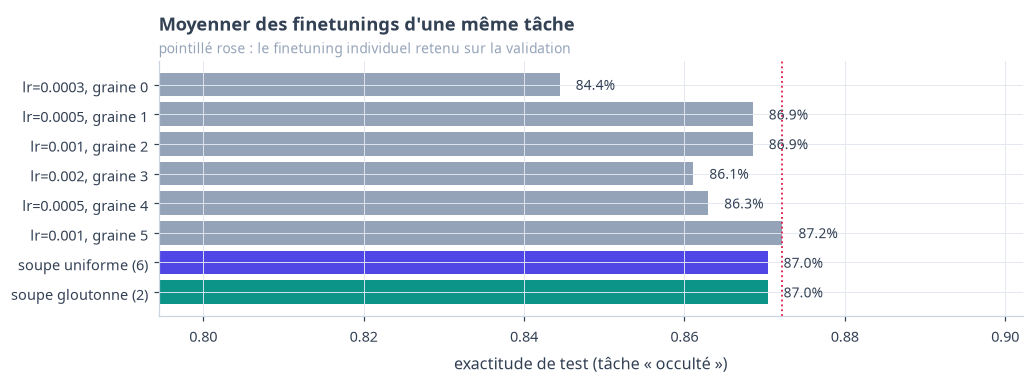

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 3.6))
cols = [GRAY] * len(ingredients) + [INDIGO, TEAL]
ax.barh(summary.index, summary["test"], color=cols)
for i, v in enumerate(summary["test"]):
    ax.text(v + 0.002, i, f"{v:.1%}", va="center", fontsize=9)
ax.axvline(best_ind["test"], color=ROSE, ls=":", lw=1.2)
ax.set_xlim(summary["test"].min() - 0.05, summary["test"].max() + 0.03); ax.invert_yaxis()
ax.set_xlabel("exactitude de test (tâche « occulté »)")
c7.title_sub(ax, "Moyenner des finetunings d'une même tâche", "pointillé rose : le finetuning individuel retenu sur la validation")
plt.tight_layout(); plt.show()

Les soupes font jeu égal avec le meilleur ingrédient (à quelques dixièmes de point près,
voir le tableau) et mieux que la plupart des autres, pour le coût d'inférence d'un seul
modèle et sans avoir à deviner à l'avance le bon réglage. Sur ce petit problème, elles ne
le dépassent pas nettement : les gains rapportés par Wortsman et al. concernent de grands
modèles pré-entraînés, dont les finetunings restent dans un même bassin très plat. La
version gloutonne protège contre les ingrédients nuisibles (finetuning parti trop loin).

> **À retenir.** Moyenner plusieurs finetunings d'une même base et d'une même tâche est un
> moyen gratuit (à l'inférence) d'obtenir au moins la qualité du meilleur réglage sans
> avoir à le choisir ; la variante gloutonne écarte les ingrédients nuisibles.

## Exercice 7.11 : SLERP

**Énoncé.**

1. Montrer que pour deux vecteurs unitaires $v_0, v_1$ d'angle $\Omega \in\, ]0, \pi[$,
   $\text{slerp}(v_0, v_1; t)$ est unitaire pour tout $t$, et que l'angle entre $v_0$ et le
   résultat vaut $t\Omega$.
2. Calculer le milieu ($t = 1/2$) de deux vecteurs unitaires orthogonaux par SLERP et par
   moyenne linéaire.
3. SLERP ne fusionne que deux vecteurs. Pour trois vecteurs de tâche, comparer
   $\text{slerp}(\text{slerp}(a, b; 1/2), c; 1/3)$, $\text{slerp}(\text{slerp}(b, c; 1/2), a; 1/3)$
   et la moyenne. L'ordre importe-t-il ?

**Rappels.** Cours 4, section 3 :
$\text{slerp}(v_0, v_1; t) = \frac{\sin((1-t)\Omega)}{\sin\Omega} v_0 + \frac{\sin(t\Omega)}{\sin\Omega} v_1$.

**Solution.**

*1.* Plaçons-nous dans le plan de $v_0, v_1$ avec une base orthonormée $(v_0, u)$ où
$v_1 = \cos\Omega\, v_0 + \sin\Omega\, u$. En remplaçant :
$\text{slerp} = \frac{\sin((1-t)\Omega) + \sin(t\Omega)\cos\Omega}{\sin\Omega} v_0 + \sin(t\Omega)\, u$.
Avec $\sin((1-t)\Omega) = \sin\Omega\cos(t\Omega) - \cos\Omega\sin(t\Omega)$, le premier
coefficient vaut $\cos(t\Omega)$ : $\text{slerp} = \cos(t\Omega)\, v_0 + \sin(t\Omega)\, u$,
vecteur unitaire faisant l'angle $t\Omega$ avec $v_0$. $\blacksquare$

*2.* $\Omega = \pi/2$ : SLERP donne $\frac{\sin(\pi/4)}{1}(v_0 + v_1) = (v_0 + v_1)/\sqrt 2$, de
norme 1 ; la moyenne linéaire $(v_0 + v_1)/2$ a une norme $1/\sqrt 2 \approx 0{,}707$.

*3.* La moyenne est symétrique ; la cascade SLERP ne l'est pas en général (la sphère n'est
pas plate), mais les écarts sont faibles quand les angles sont petits. On le vérifie sur
des vecteurs aléatoires et sur les vecteurs de tâche du réseau `digits`.

In [9]:
rng = np.random.default_rng(1)
v0 = np.array([1.0, 0.0, 0.0]); v1 = np.array([0.0, 1.0, 0.0])
m_s, m_l = c7.slerp(v0, v1, 0.5), 0.5 * (v0 + v1)
print("SLERP :", m_s.round(4), "norme", round(np.linalg.norm(m_s), 4), " | linéaire :", m_l, "norme", round(np.linalg.norm(m_l), 4))
a, b = rng.normal(size=50), rng.normal(size=50)
a, b = a / np.linalg.norm(a), b / np.linalg.norm(b)
Om = np.arccos(a @ b)
chk = pd.DataFrame([{"t": t, "norme": np.linalg.norm(c7.slerp(a, b, t)),
                     "angle(v0, slerp) / Omega": np.arccos(np.clip(a @ c7.slerp(a, b, t), -1, 1)) / Om} for t in [0.1, 0.3, 0.5, 0.9]])
display(chk.round(6))

tvs = list(S.task_vectors.values())


def cascade(x, y, z):
    return c7.slerp(c7.slerp(x, y, 0.5), z, 1 / 3)


A_, B_, C_ = tvs
merges = {"slerp((a,b),c)": cascade(A_, B_, C_), "slerp((b,c),a)": cascade(B_, C_, A_),
          "slerp((a,c),b)": cascade(A_, C_, B_), "moyenne": (A_ + B_ + C_) / 3}
res = pd.DataFrame({k: {"norme": np.linalg.norm(v), "écart relatif à slerp((a,b),c)": np.linalg.norm(v - merges["slerp((a,b),c)"]) / np.linalg.norm(merges["slerp((a,b),c)"]),
                        **{f"exactitude {d}": S.evaluate(S.base + 1.2 * v)[d] for d in ["bruité", "occulté", "décalé"]}}
                    for k, v in merges.items()}).T
res.round(4)

SLERP : [0.7071 0.7071 0.    ] norme 1.0  | linéaire : [0.5 0.5 0. ] norme 0.7071


,t,norme,"angle(v0, slerp) / Omega"
0,0.1,1.0,0.1
1,0.3,1.0,0.3
2,0.5,1.0,0.5
3,0.9,1.0,0.9


,norme,"écart relatif à slerp((a,b),c)",exactitude bruité,exactitude occulté,exactitude décalé
"slerp((a,b),c)",3.3181,0.0000,0.6907,0.8019,0.8519
"slerp((b,c),a)",3.3181,0.1466,0.6889,0.8000,0.8796
"slerp((a,c),b)",3.3181,0.1416,0.7056,0.7926,0.8778
moyenne,1.9631,0.4160,0.7130,0.8074,0.8981


**Vérification.** La norme reste 1 et l'angle vaut exactement $t\Omega$. Pour les trois
vecteurs de tâche, les cascades donnent des résultats différents selon l'ordre (écart
relatif de l'ordre de 15 %) mais des exactitudes voisines ; toutes ont une norme plus
grande que la moyenne, qui raccourcit des vecteurs presque orthogonaux d'un facteur
proche de $1/\sqrt 3$. (On a multiplié chaque fusion par 1,2 avant de l'ajouter à la base,
comme un $\lambda$ global.)

> **À retenir.** SLERP suit le grand cercle : norme conservée, angle proportionnel à $t$.
> Pour plus de deux modèles, la cascade dépend de l'ordre, une raison de préférer d'autres
> méthodes (TIES, arithmétique des tâches) quand on fusionne beaucoup de modèles.

## Exercice 7.12 : Accumulation de gradient et poids de la perte du prompt

**Énoncé.**

1. Montrer que pour une perte définie comme la **moyenne par exemple**, accumuler les
   gradients de $k$ micro-lots de taille $m$ (chacun divisé par $k$) donne exactement le
   gradient d'un lot de $km$ exemples.
2. Notre perte de SFT est une moyenne **par token** de réponse (`c7.weighted_lm_loss`). Les
   micro-lots ayant des nombres de tokens différents, l'égalité tient-elle encore ? Le
   vérifier numériquement et proposer une correction.
3. Dans un exemple de la tâche des tickets, le prompt compte 77 tokens et la réponse 21.
   Quelle fraction du signal d'apprentissage porte sur le prompt pour $w_p$ = 0, 10 % et
   100 % ?

**Rappels.** Cours 4, sections 8 et 9 : accumulation de gradient ;
$\mathcal L = (w_p \sum_{\text{prompt}} \ell_t + \sum_{\text{réponse}} \ell_t)/(w_p n_p + n_r)$.

**Solution.**

*1.* $\nabla \frac{1}{km}\sum_{i=1}^{km} \ell_i = \frac{1}{k}\sum_{j=1}^{k} \nabla\Big(\frac{1}{m}\sum_{i \in \text{micro-lot } j} \ell_i\Big)$ :
la moyenne globale est la moyenne des moyennes de micro-lots **de même taille**.

*2.* Avec une moyenne par token, le micro-lot $j$ a $n_j$ tokens : la perte du grand lot
est $\frac{\sum_j \sum_{t \in j} \ell_t}{\sum_j n_j}$, alors que l'accumulation calcule
$\frac{1}{k}\sum_j \frac{1}{n_j}\sum_{t\in j}\ell_t$. Les deux diffèrent dès que les $n_j$
diffèrent : les tokens des micro-lots courts pèsent davantage. Correction : accumuler les
**sommes** de pertes et diviser par le nombre **total** de tokens du lot effectif (connu
à l'avance en comptant les tokens de réponse des $k$ micro-lots).

*3.* Fraction $= w_p n_p / (w_p n_p + n_r)$ : 0 % ; $7{,}7 / 28{,}7 = 26{,}8$ % ;
$77 / 98 = 78{,}6$ %.

In [10]:
torch.manual_seed(0)
V_, L_ = 50, 12
logits = torch.randn(4, L_, V_, requires_grad=True)
ids = torch.randint(0, V_, (4, L_))
w = torch.zeros(4, L_)
for i, n_resp in enumerate([2, 9, 3, 10]):  # nombres de tokens de réponse très différents
    w[i, L_ - n_resp:] = 1.0


def grad(fn):
    if logits.grad is not None:
        logits.grad = None
    fn().backward()
    return logits.grad.clone()


g_full = grad(lambda: c7.weighted_lm_loss(logits, ids, w))
g_acc = grad(lambda: sum(c7.weighted_lm_loss(logits[j:j + 2], ids[j:j + 2], w[j:j + 2]) for j in (0, 2)) / 2)


def summed(j):  # somme des pertes du micro-lot, normalisée par le total de tokens du lot effectif
    import torch.nn.functional as F
    lg, tg, ww = logits[j:j + 2, :-1], ids[j:j + 2, 1:], w[j:j + 2, 1:]
    nll = F.cross_entropy(lg.reshape(-1, V_), tg.reshape(-1), reduction="none").view_as(tg)
    return (nll * ww).sum() / w[:, 1:].sum()


g_fix = grad(lambda: summed(0) + summed(2))
print(f"écart max, accumulation naïve : {(g_acc - g_full).abs().max().item():.2e}")
print(f"écart max, accumulation corrigée : {(g_fix - g_full).abs().max().item():.2e}")
fr = pd.DataFrame({"w_p": [0, 0.1, 1.0]})
fr["fraction du signal sur le prompt"] = fr["w_p"] * 77 / (fr["w_p"] * 77 + 21)
fr.round(3)

écart max, accumulation naïve : 3.77e-03
écart max, accumulation corrigée : 0.00e+00


,w_p,fraction du signal sur le prompt
0,0.0,0.000
1,0.1,0.268
2,1.0,0.786


**Vérification graphique** : poids effectif de chaque token de réponse dans le gradient,
selon la méthode (lot de 4 exemples découpé en 2 micro-lots de 2).

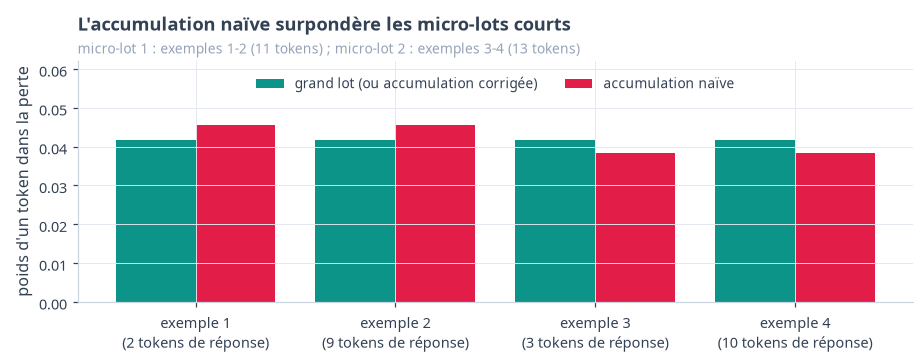

In [11]:
n_resp = np.array([2, 9, 3, 10])
eff_full = np.repeat(1 / n_resp.sum(), 4)
eff_naive = np.array([1 / (2 * (n_resp[0] + n_resp[1]))] * 2 + [1 / (2 * (n_resp[2] + n_resp[3]))] * 2)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
xk = np.arange(4)
ax.bar(xk - 0.2, eff_full, 0.4, color=TEAL, label="grand lot (ou accumulation corrigée)")
ax.bar(xk + 0.2, eff_naive, 0.4, color=ROSE, label="accumulation naïve")
ax.set_xticks(xk, [f"exemple {i + 1}\n({n} tokens de réponse)" for i, n in enumerate(n_resp)])
ax.set_ylabel("poids d'un token dans la perte"); ax.set_ylim(0, 0.062); ax.legend(fontsize=9, ncol=2, loc="upper center")
c7.title_sub(ax, "L'accumulation naïve surpondère les micro-lots courts", "micro-lot 1 : exemples 1-2 (11 tokens) ; micro-lot 2 : exemples 3-4 (13 tokens)")
plt.tight_layout(); plt.show()

L'écart est ici modéré (11 contre 13 tokens), mais il grandit avec l'hétérogénéité des
longueurs : un micro-lot de réponses très courtes recevrait un poids disproportionné. Les
frameworks récents normalisent par le nombre total de tokens du lot effectif pour cette
raison. Notre `c7.train_sft` utilise la version naïve, acceptable car nos réponses ont des
longueurs voisines.

> **À retenir.** L'accumulation de gradient est exacte pour une moyenne par exemple, mais
> une moyenne par token demande de normaliser par le total de tokens du lot effectif. Avec
> $w_p = 10$ %, plus du quart du signal porte encore sur le prompt quand celui-ci est
> quatre fois plus long que la réponse.

In [12]:
llm.free_gpu()